# $\phi^4$ lattice: train a single-site prior and sample with it

Trains the single-site prior $p_0(\phi)\propto e^{-V(\phi)}$, $V(\phi)=(\phi^2-1)^2$, from exact samples, then runs the [$\phi^4$ example](README.md) with it. Training takes a few minutes on CPU and the example about 15 minutes with CUDA; the trained prior, the settings and the results go to `runs/phi4_notebook_<timestamp>/`.

In [1]:
import os
import sys  # noqa: F401, used by the shell command of the sampling cell
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from IPython.display import Image, display
from scipy.integrate import cumulative_trapezoid, trapezoid
from scipy.stats import gaussian_kde

from ggpa.priors import ddpm, v_to_eps
from ggpa.priors.networks import ResidualMLP, load_net
from ggpa.systems.phi4 import z2

%config InlineBackend.figure_format = 'retina'
os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file()))  # repository root
plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.9, "lines.linewidth": 1.7})
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
torch.set_num_threads(4)
device = torch.device("cpu")  # the example below runs on CUDA
run = Path("runs") / time.strftime("phi4_notebook_%Y%m%d_%H%M%S")
run.mkdir(parents=True)

## Data

Inverse-CDF samples of $p_0$, reflected so that the data are exactly symmetric.

data: (200000,), mean -5.7e-19, variance 0.8311 (exact 0.8327)


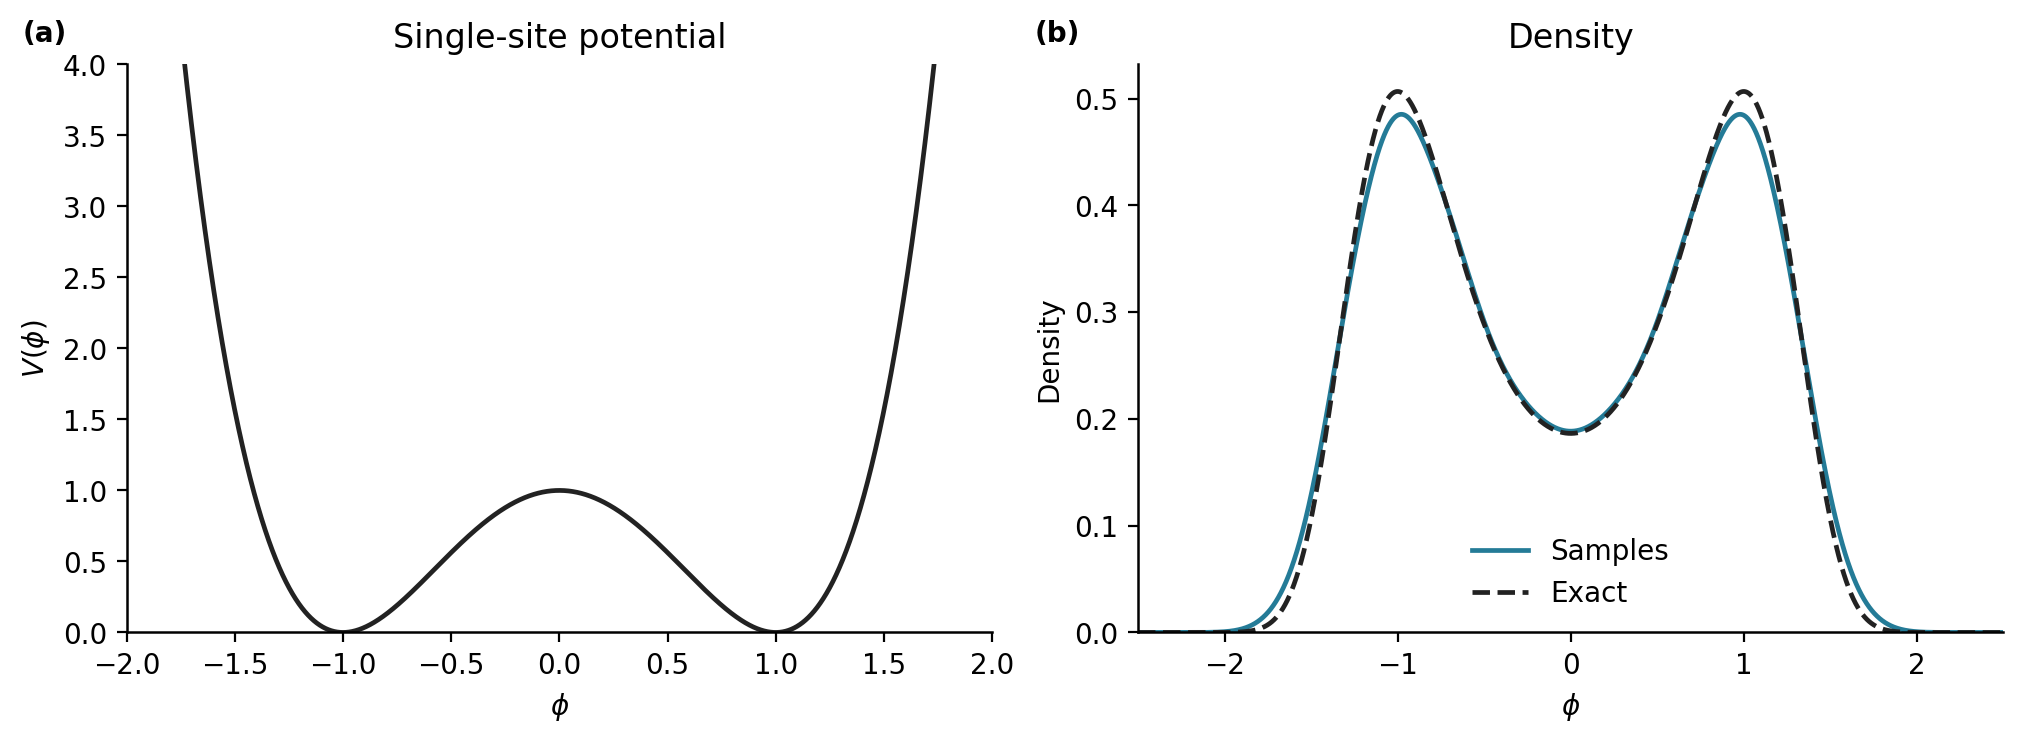

In [2]:
def potential(x):
    return (x**2 - 1) ** 2


x = np.linspace(-4, 4, 65537)
p = np.exp(-potential(x))
p /= trapezoid(p, x)
cdf = cumulative_trapezoid(p, x, initial=0)
exact_var = trapezoid(x**2 * p, x)

data = np.interp(np.random.rand(100_000), cdf, x)
data = np.concatenate([data, -data])
print(f"data: {data.shape}, mean {data.mean():.1e}, variance {data.var():.4f} (exact {exact_var:.4f})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
ax1.plot(x, potential(x), color="#222222")
ax1.set(xlim=(-2, 2), ylim=(0, 4), xlabel=r"$\phi$", ylabel=r"$V(\phi)$", title="Single-site potential")
ax2.plot(x, gaussian_kde(data[::10])(x), color="#247b97", label="Samples")
ax2.plot(x, p, "--", color="#222222", label="Exact")
ax2.set(xlim=(-2.5, 2.5), ylim=(0, None), xlabel=r"$\phi$", ylabel="Density", title="Density")
ax2.legend(frameon=False)
for letter, ax in zip("ab", (ax1, ax2), strict=True):
    ax.spines[["top", "right"]].set_visible(False)
    ax.text(-0.12, 1.04, f"({letter})", transform=ax.transAxes, fontweight="bold")
plt.show()

## Training

Score matching with the target score mixed with the noise ([arXiv:2402.08667](https://arxiv.org/abs/2402.08667)) on the cosine schedule with $T=1000$ levels, $y=\alpha_t x_0+\sigma_t\epsilon$:

$$
\mathcal L=\mathbb E\Big\lVert s_\theta(y,t)-(1-w_t)\frac{\nabla\log p_0(x_0)}{\alpha_t}+w_t\frac{\epsilon}{\sigma_t}\Big\rVert^2,\qquad
w_t=\frac{\sigma_t^2}{\sigma_t^2+\alpha_t^2\nu},
$$

with $\nu=\mathrm{Var}(\phi\mid\phi>0)$, the variance of one well. The network predicts the velocity $v_\theta$, odd in $y$ by the symmetry of $p_0$, and $s_\theta=-(\alpha_t v_\theta+\sigma_t y)/\sigma_t$.

In [3]:
v_mix = trapezoid(x**2 * p, x) - trapezoid(np.abs(x) * p, x) ** 2
print(f"nu: {v_mix:.6f}")

T = 1000
f = np.cos((np.arange(T + 1) / T + 0.008) / 1.008 * np.pi / 2) ** 2
alpha_bar = torch.tensor(np.cumprod(1 - np.clip(1 - f[1:] / f[:-1], 0, 0.999)), dtype=torch.float32)
alpha, sigma = alpha_bar.sqrt().to(device), (1 - alpha_bar).sqrt().to(device)

n_epochs = 200
batch_size = 2048
lr = 1e-3
data_t = torch.tensor(data, dtype=torch.float32, device=device)
config = dict(input_dim=1, output_dim=1, hidden_dim=16, time_embed_dim=16, n_blocks=3)
net = ResidualMLP(**config).to(device)
v_net = z2(net)
optimizer = torch.optim.Adam(net.parameters(), lr=lr)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)
print(f"parameters: {sum(w.numel() for w in net.parameters())}")

start = time.perf_counter()
for epoch in range(n_epochs):
    perm = torch.randperm(len(data_t), device=device)
    epoch_loss = 0.0
    for i in range(0, len(data_t), batch_size):
        x0 = data_t[perm[i : i + batch_size]]
        k = torch.randint(T, (len(x0),), device=device)
        eps = torch.randn_like(x0)
        a, s = alpha[k], sigma[k]
        y = a * x0 + s * eps
        label = (a * v_mix * (-4 * x0 * (x0**2 - 1)) - s * eps) / (s**2 + a**2 * v_mix)
        score = -a / s * v_net(y[:, None], k / (T - 1))[:, 0] - y  # eps = alpha * v + sigma * y
        loss = (score - label).pow(2).mean()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.detach()
    scheduler.step()
    if (epoch + 1) % 20 == 0:
        print(f"epoch {epoch + 1}/{n_epochs}, loss {epoch_loss.item() * batch_size / len(data_t):.4f}")
print(f"training: {time.perf_counter() - start:.0f} s")

ckpt = {
    "format": "ggpa-prior/1",
    "net": {"class": "ResidualMLP", "config": config, "state_dict": net.state_dict()},
    "output": "v",
    "kernel": {"family": "gaussian", "shape": [1], "schedule": {"kind": "discrete_vp", "alpha_bar": alpha_bar}},
    "provenance": {"notebook": "examples/phi4/train_and_sample.ipynb", "seed": seed},
}
torch.save(ckpt, run / "prior.pt")
print(f"saved {run / 'prior.pt'}")

nu: 0.148167


parameters: 3569


epoch 20/200, loss 0.5867


epoch 40/200, loss 0.5800


epoch 60/200, loss 0.5836


epoch 80/200, loss 0.5797


... (2 outputs left out)

epoch 140/200, loss 0.5794


epoch 160/200, loss 0.5739


epoch 180/200, loss 0.5738


epoch 200/200, loss 0.5778
training: 47 s
saved runs/phi4_notebook_20261101_144440/prior.pt


## Check

Draws from noise at $t=1$ with the trained and the bundled prior, against the exact density.

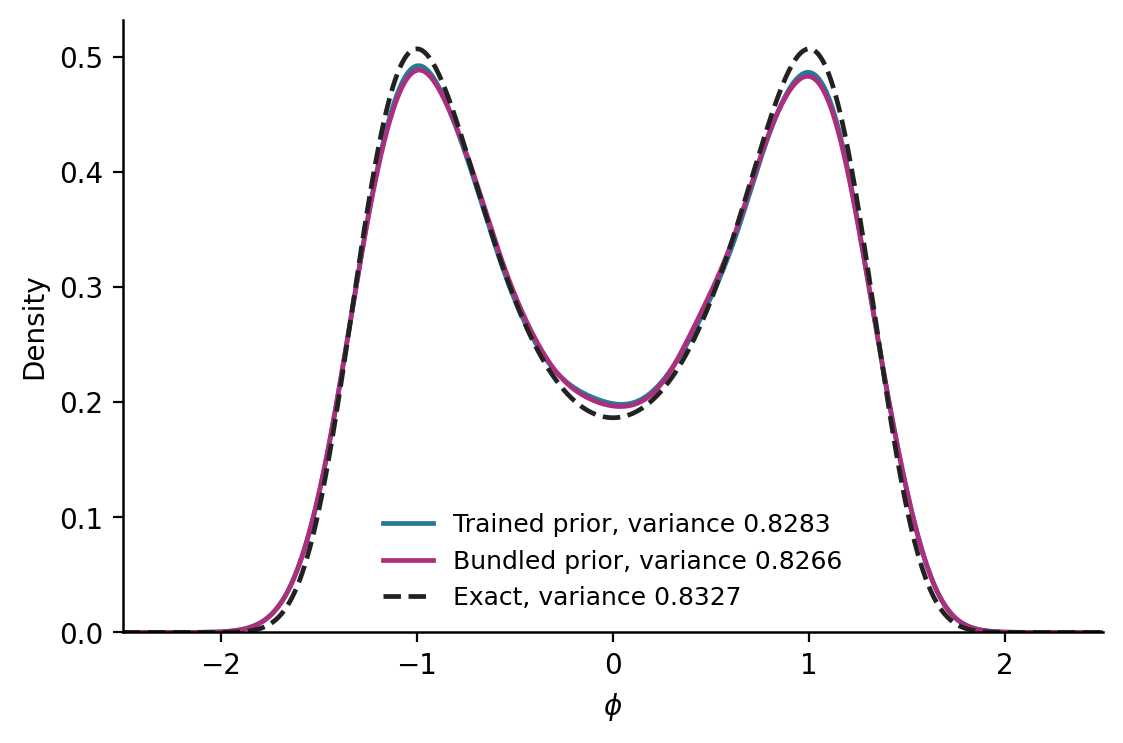

In [4]:
def draw(path, n=50_000, seed=0):
    net, kernel, _ = load_net(path, device)
    prior = ddpm(v_to_eps(z2(net), kernel), kernel)
    gen = torch.Generator(device).manual_seed(seed)
    y = torch.randn(n, 1, generator=gen, device=device)
    return prior.denoise(y, torch.ones(n, dtype=torch.float64, device=device), gen).cpu().numpy().ravel()


fig, ax = plt.subplots(figsize=(5.5, 3.6), layout="constrained")
for (name, path), color in zip(
    (("Trained prior", run / "prior.pt"), ("Bundled prior", "checkpoints/phi4_prior.pt")),
    ("#247b97", "#ad2e7e"),
    strict=True,
):
    x_gen = draw(path)
    ax.plot(x, gaussian_kde(x_gen)(x), color=color, label=f"{name}, variance {x_gen.var():.4f}")
ax.plot(x, p, "--", color="#222222", label=f"Exact, variance {exact_var:.4f}")
ax.set(xlim=(-2.5, 2.5), ylim=(0, None), xlabel=r"$\phi$", ylabel="Density")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=9)
plt.show()

## Sampling

The example with the trained prior, from a copy of its settings.

ggpa: J=0.2, h=0


metropolis: J=0.2, h=0


ggpa: J=0.44, h=0


metropolis: J=0.44, h=0


ggpa: J=0.7, h=0


metropolis: J=0.7, h=0


Saved runs/phi4_notebook_20261101_144440/sampling/figures/comparison.png (537 s)


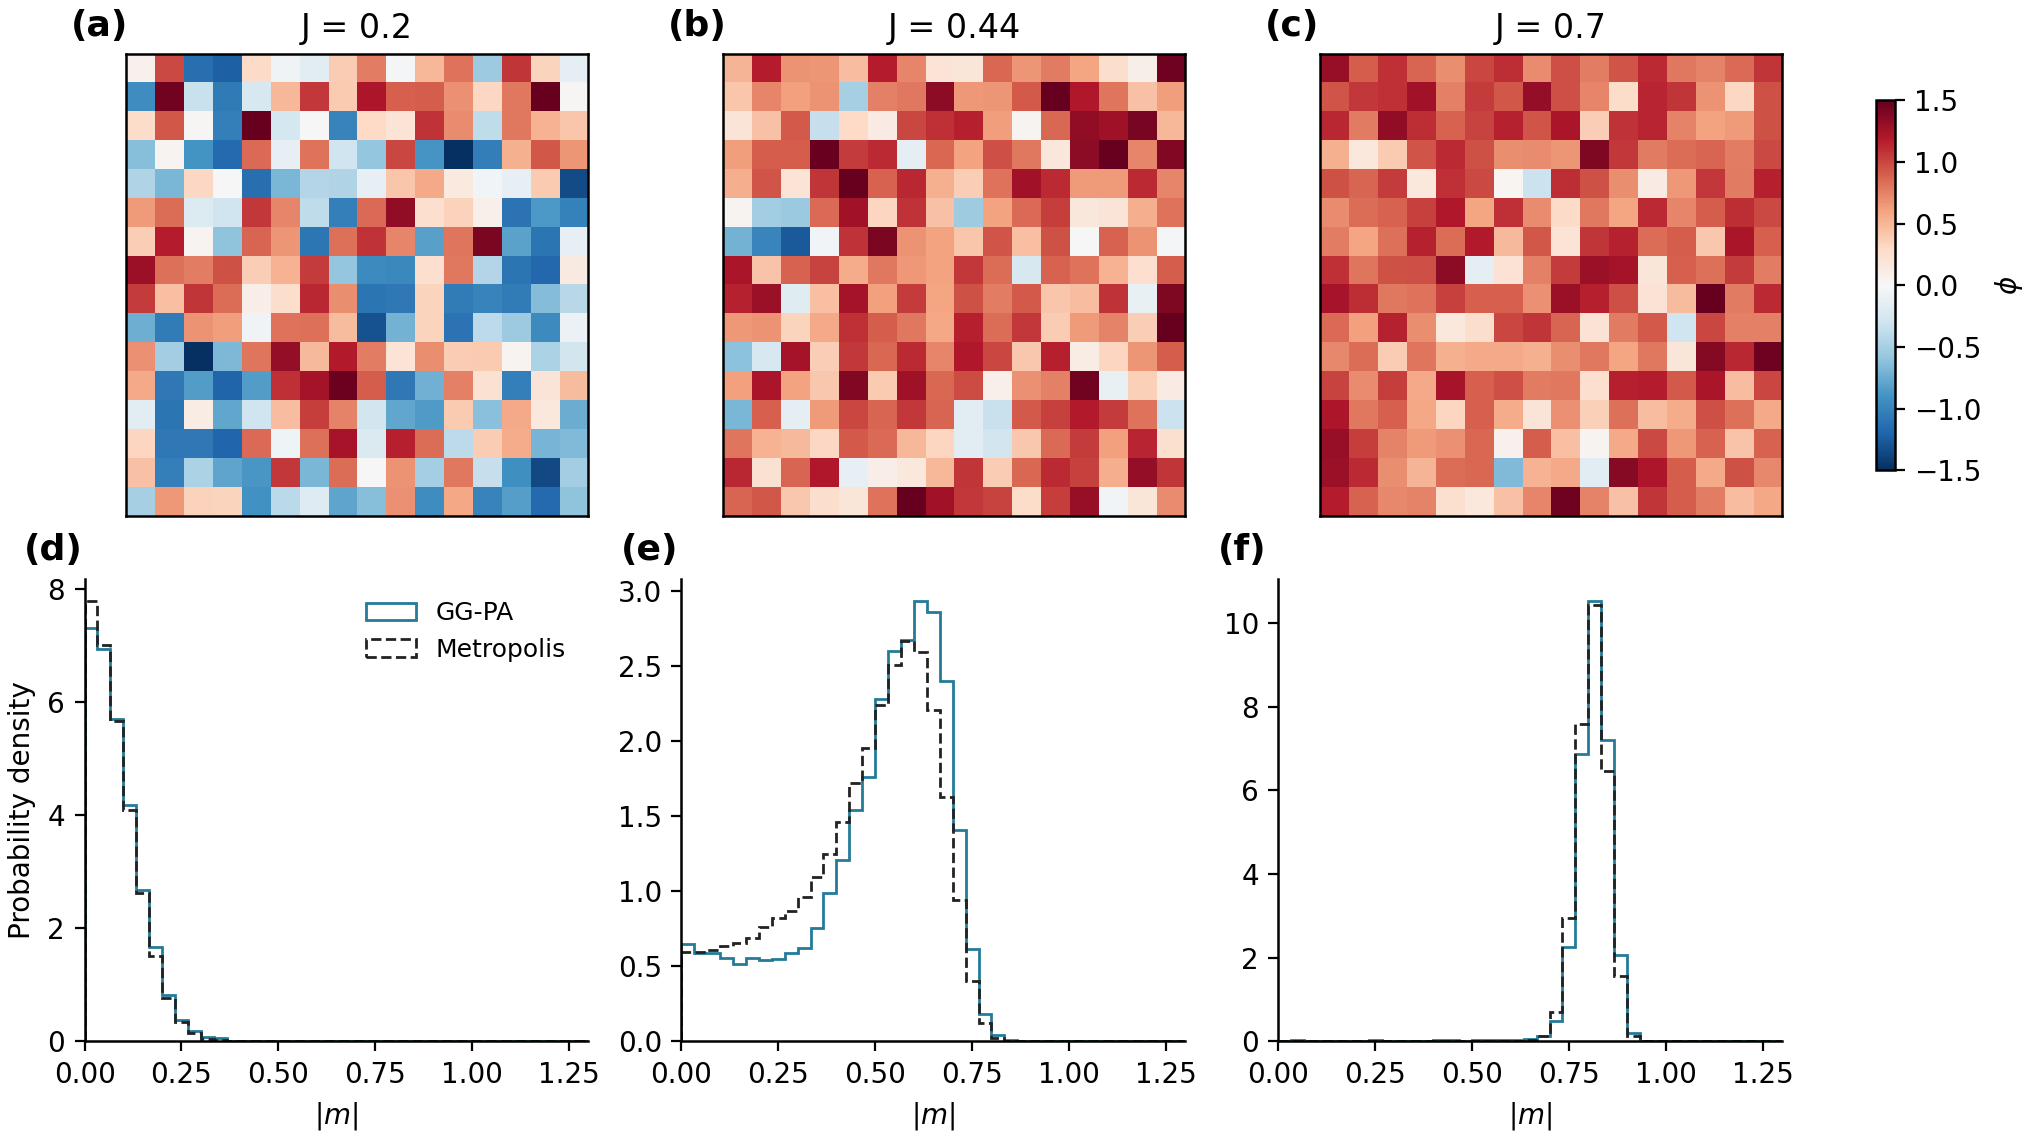

In [5]:
settings = yaml.safe_load(Path("examples/phi4/settings.yaml").read_text())
settings["sample"]["checkpoint"] = str(run / "prior.pt")
(run / "settings.yaml").write_text(yaml.safe_dump(settings, sort_keys=False))

!{sys.executable} examples/phi4/example_phi4.py --config {run}/settings.yaml --out {run}/sampling
display(Image(filename=str(run / "sampling/figures/comparison.png"), width=1000))